In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('water_potability.csv')

print("=== IDENTIFIKASI DATASET ===")
print("Nama Dataset: Water Potability")
print("Sumber: Kaggle - adityakadiwal/water-potability")
print("Jenis Data: Tabular / Angka (Bukan Teks, Bukan Image)")
print(f"Jumlah Data (baris): {df.shape[0]}")
print(f"Jumlah Variabel (kolom): {df.shape[1]}")
print(f"Nama Variabel: {list(df.columns)}")
print(f"Data Fitur (X): {list(df.drop('Potability', axis=1).columns)}")
print(f"Data Target (y): ['Potability']")
print(f"Isi Label: {sorted(df['Potability'].dropna().unique())} -> 0=Tidak Layak, 1=Layak")
print("\nKESIMPULAN SEMENTARA: Klasifikasi BINER")
print(df.head())

=== IDENTIFIKASI DATASET ===
Nama Dataset: Water Potability
Sumber: Kaggle - adityakadiwal/water-potability
Jenis Data: Tabular / Angka (Bukan Teks, Bukan Image)
Jumlah Data (baris): 3276
Jumlah Variabel (kolom): 10
Nama Variabel: ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']
Data Fitur (X): ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']
Data Target (y): ['Potability']
Isi Label: [np.int64(0), np.int64(1)] -> 0=Tidak Layak, 1=Layak

KESIMPULAN SEMENTARA: Klasifikasi BINER
         ph    Hardness        Solids  Chloramines     Sulfate  Conductivity  \
0       NaN  204.890455  20791.318981     7.300212  368.516441    564.308654   
1  3.716080  129.422921  18630.057858     6.635246         NaN    592.885359   
2  8.099124  224.236259  19909.541732     9.275884         NaN    418.606213   
3  8.316766  214.373394  22018.417441   

Missing per kolom:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Jumlah per kelas:
Potability
0    1998
1    1278
Name: count, dtype: int64


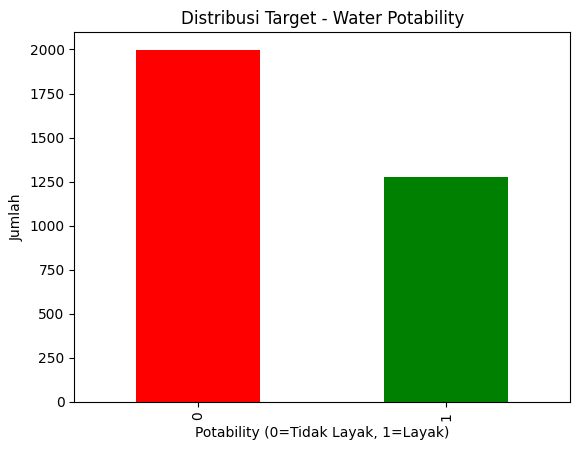

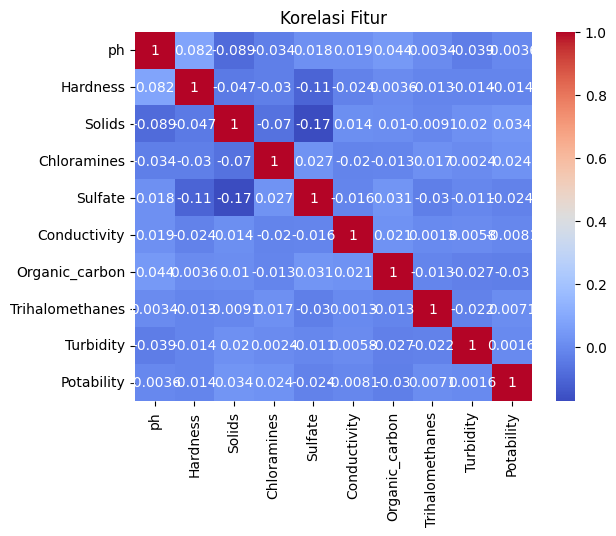

In [8]:
print("Missing per kolom:")
print(df.isnull().sum())
print("\nJumlah per kelas:")
print(df['Potability'].value_counts())

df['Potability'].value_counts().plot(kind='bar', color=['red','green'])
plt.title('Distribusi Target - Water Potability')
plt.xlabel('Potability (0=Tidak Layak, 1=Layak)')
plt.ylabel('Jumlah')
plt.show()

sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Korelasi Fitur')
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

df = df.fillna(df.mean(numeric_only=True))

X = df.drop('Potability', axis=1)
y = df['Potability']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

X_train: (2620, 9), X_test: (656, 9)
y_train: (2620,), y_test: (656,)


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model1 = LogisticRegression(max_iter=1000)
model1.fit(X_train_s, y_train)
pred1 = model1.predict(X_test_s)
print("Logistic Regression Accuracy:", accuracy_score(y_test, pred1))

model2 = RandomForestClassifier(n_estimators=100, random_state=42)
model2.fit(X_train_s, y_train)
pred2 = model2.predict(X_test_s)
print("Random Forest Accuracy:", accuracy_score(y_test, pred2))

if accuracy_score(y_test, pred2) >= accuracy_score(y_test, pred1):
    y_pred = pred2
    print("Model Terbaik: Random Forest")
else:
    y_pred = pred1
    print("Model Terbaik: Logistic Regression")

Logistic Regression Accuracy: 0.6097560975609756
Random Forest Accuracy: 0.6554878048780488
Model Terbaik: Random Forest


              precision    recall  f1-score   support

           0       0.67      0.88      0.76       400
           1       0.62      0.31      0.41       256

    accuracy                           0.66       656
   macro avg       0.64      0.59      0.59       656
weighted avg       0.65      0.66      0.62       656



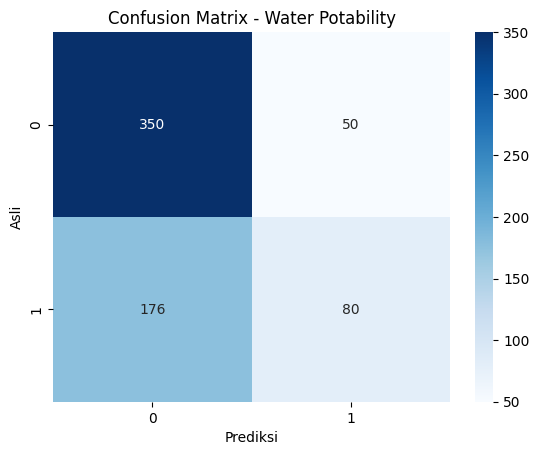

=== KESIMPULAN AKHIR ===
Jenis Klasifikasi: BINER, karena target hanya 2 kelas (0 dan 1)
Accuracy Akhir: 0.6555
Fitur: 9 kolom ph, Hardness, dll. Target: Potability


In [11]:
print(classification_report(y_test, y_pred))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Water Potability')
plt.xlabel('Prediksi')
plt.ylabel('Asli')
plt.show()

print("=== KESIMPULAN AKHIR ===")
print("Jenis Klasifikasi: BINER, karena target hanya 2 kelas (0 dan 1)")
print(f"Accuracy Akhir: {accuracy_score(y_test, y_pred):.4f}")
print("Fitur: 9 kolom ph, Hardness, dll. Target: Potability")